# T-Lab 2026 RecSys — Задание 2. RL-дообучение последовательной рекомендательной модели

**Данные:** Yambda-50M (Яндекс Музыка): 10k пользователей, ~46M прослушиваний, точные timestamps, `played_ratio_pct`, длина трека.

**Пайплайн:**
1. **Base:** GPT-2 (токены — id треков) обучается на next-item prediction.
2. **Reward model (RM):** причинный трансформер над историей *(трек, доля дослушивания)* предсказывает для трека-кандидата
   `P(Listen+)` (дослушает ≥ 50%) и `P(continue)` (сессия продолжится ≥ 30 минут — прокси долгосрочной цели).
   Обучаются **две независимые RM**: `RM-train` даёт награду для RL, а `RM-judge` (другие сид, архитектура и подвыборка)
   используется только для оценки, чтобы ловить *reward hacking*, то есть эксплуатацию ошибок конкретной RM.
3. **RL:** REINFORCE с групповым бейзлайном (GRPO-style, G сэмплов на контекст) и **точным KL** к базовой модели
   (на одном шаге распределение категориальное по всему словарю, поэтому KL считается точно).
   Оптимум задачи `max E[R] − β·KL(π‖π_ref)` известен аналитически: `π* ∝ π_ref · exp(R/β)`. Мы считаем его как
   reference-точку, что позволяет проверить, куда сходится RL.
4. **Анализ:** компромисс между релевантностью и наградой (кривая Парето по β), разные функции награды
   (Listen+, время прослушивания, продолжение сессии), поведение модели (популярность, покрытие, длина треков, повторы),
   генерация на несколько шагов вперёд.

**Протокол:** глобальный временной сплит — train: всё до предпоследнего дня; valid: предпоследний день (ранняя остановка,
валидация RM); test: последний день. Все модели оцениваются на **одних и тех же** контекстах и таргетах.

В Kaggle: **Accelerator → GPU T4 / P100**, **Internet → On**.

In [1]:
import os, time, gc, copy, math, json
os.system("pip install -q -U huggingface_hub transformers")
import numpy as np
import polars as pl
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from transformers import GPT2Config, GPT2LMHeadModel
import matplotlib
import matplotlib.pyplot as plt

IN_KAGGLE = os.path.exists("/kaggle")
DATA_DIR = "/kaggle/working/yambda" if IN_KAGGLE else os.environ.get("DATA_DIR", "data")
OUT_DIR = "/kaggle/working/out2" if IN_KAGGLE else "out2"
os.makedirs(OUT_DIR, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
QUICK = int(os.environ.get("QUICK", 0))              # 1 = быстрый smoke-test на CPU
SAMPLE_USERS = int(os.environ.get("SAMPLE_USERS", 0))
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DAY, GAP_CONT = 86400, 1800

# гиперпараметры
V = 5000 if QUICK else 30000          # размер словаря треков (top-V по популярности в train)
L = 64 if QUICK else 200              # контекст GPT-2
GPT_DIM, GPT_LAYERS, GPT_HEADS = (64, 2, 2) if QUICK else (256, 4, 4)
GPT_EPOCHS, GPT_BS, GPT_LR = (1, 32, 2e-3) if QUICK else (3, 64, 1e-3)
RM_W = 32 if QUICK else 96            # окно RM (история W-1 + кандидат)
RM_DAYS = 10 if QUICK else 60         # таргеты RM: последние RM_DAYS дней train
RM_EPOCHS = 1 if QUICK else 2
RL_STEPS, RL_B, RL_G, RL_LR = (30, 32, 8, 1e-4) if QUICK else (300, 128, 8, 1e-4)
K = 10
print("device:", DEV, "| quick:", QUICK, "| V:", V, "| L:", L)

device: cuda | quick: 0 | V: 30000 | L: 200


## 1. Данные

In [2]:
from huggingface_hub import hf_hub_download
p_ev = hf_hub_download("yandex/yambda", "flat/50m/multi_event.parquet", repo_type="dataset", local_dir=DATA_DIR)
p_art = hf_hub_download("yandex/yambda", "artist_item_mapping.parquet", repo_type="dataset", local_dir=DATA_DIR)

ev = (pl.read_parquet(p_ev).filter(pl.col("event_type") == "listen")
      .select("uid", "item_id", pl.col("timestamp").cast(pl.Int64), "played_ratio_pct", "track_length_seconds", "is_organic"))
if SAMPLE_USERS:
    ev = ev.join(ev.select(pl.col("uid").unique()).sample(SAMPLE_USERS, seed=SEED), on="uid")
ev = ev.with_row_index("row").sort(["uid", "timestamp", "row"])
# продолжение сессии: следующее прослушивание пользователя в пределах 30 минут (считаем ДО фильтрации словаря)
ev = ev.with_columns(cont=((pl.col("timestamp").shift(-1).over("uid") - pl.col("timestamp")) <= GAP_CONT).fill_null(False).cast(pl.Int8))

T_MAX = ev["timestamp"].max()
test_start = T_MAX - DAY
valid_start = test_start - DAY

vocab = (ev.filter(pl.col("timestamp") < valid_start).group_by("item_id").len().sort("len", descending=True).head(V)
         .with_row_index("tok", offset=1).select("item_id", pl.col("tok").cast(pl.Int32), pop="len"))
cover = ev.filter(pl.col("timestamp") < valid_start).join(vocab, on="item_id").height / ev.filter(pl.col("timestamp") < valid_start).height
print(f"словарь {V} треков покрывает {cover:.1%} прослушиваний train")

ev = (ev.join(vocab.select("item_id", "tok"), on="item_id").sort("row")
      .with_columns(fb=pl.when(pl.col("played_ratio_pct") < 10).then(1).when(pl.col("played_ratio_pct") < 50).then(2)
                    .when(pl.col("played_ratio_pct") < 90).then(3).otherwise(4).cast(pl.Int8)))
V1 = V + 1                      # 0 = PAD
UNK_FB = 5                      # «отклик неизвестен» (для сгенерированных моделью треков)

TOK = ev["tok"].to_numpy().astype(np.int64)
FB = ev["fb"].to_numpy().astype(np.int64)
PLAYED = ev["played_ratio_pct"].to_numpy().astype(np.int64)
CONT = ev["cont"].to_numpy().astype(np.float32)
N = len(TOK)

ust = ev.group_by("uid", maintain_order=True).agg(
    n=pl.len(), n_vs=(pl.col("timestamp") < valid_start).sum(), n_ts=(pl.col("timestamp") < test_start).sum(),
    n_rm=(pl.col("timestamp") < valid_start - RM_DAYS * DAY).sum())
UIDS = ust["uid"].to_numpy()
NU = ust["n"].to_numpy().astype(np.int64)
OFF = np.concatenate([[0], np.cumsum(NU)[:-1]])
IVS, ITS, IRM = (ust[c].to_numpy().astype(np.int64) for c in ["n_vs", "n_ts", "n_rm"])

# метаданные токенов
meta = (ev.group_by("tok").agg(len_s=pl.col("track_length_seconds").median())
        .join(vocab.select("tok", "pop"), on="tok", how="right"))
TOK_LEN = np.zeros(V1, np.float32); TOK_LEN[meta["tok"].to_numpy()] = meta["len_s"].fill_null(200).to_numpy()
TOK_POP = np.zeros(V1, np.float32); TOK_POP[meta["tok"].to_numpy()] = meta["pop"].to_numpy()
art = pl.read_parquet(p_art).group_by("item_id").agg(pl.col("artist_id").min())
ta = vocab.join(art, on="item_id", how="left")
TOK_ART = np.zeros(V1, np.int64); TOK_ART[ta["tok"].to_numpy()] = ta["artist_id"].fill_null(0).to_numpy()
TOP1PCT = np.zeros(V1, bool); TOP1PCT[1:max(2, V // 100) + 1] = True    # токены отсортированы по популярности
print(f"событий после фильтра: {N:,}, пользователей: {len(UIDS)}")
print(ust.select(pl.col("n").mean().alias("avg_len"), (pl.col("n") - pl.col("n_ts")).gt(0).sum().alias("users_with_test")))

словарь 30000 треков покрывает 72.0% прослушиваний train
событий после фильтра: 33,420,359, пользователей: 9223
shape: (1, 2)
┌─────────────┬─────────────────┐
│ avg_len     ┆ users_with_test │
│ ---         ┆ ---             │
│ f64         ┆ u32             │
╞═════════════╪═════════════════╡
│ 3623.588746 ┆ 4610            │
└─────────────┴─────────────────┘


### Длина трека и дослушивание
Короткие треки дослушивают чаще, так что награда «доля дослушивания» может подталкивать модель к коротким трекам.
Проверяем это на сырых данных; дальше это понадобится для анализа поведения RL.

In [3]:
lb = (ev.filter(pl.col("timestamp") < valid_start)
      .with_columns(len_bucket=pl.col("track_length_seconds").cut([60, 120, 180, 240, 300, 420]))
      .group_by("len_bucket").agg(listen_plus=(pl.col("played_ratio_pct") >= 50).mean(), n=pl.len()).sort("len_bucket"))
print(lb)

/tmp/ipykernel_342/3906026286.py:2: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  .with_columns(len_bucket=pl.col("track_length_seconds").cut([60, 120, 180, 240, 300, 420]))


shape: (7, 3)
┌────────────┬─────────────┬──────────┐
│ len_bucket ┆ listen_plus ┆ n        │
│ ---        ┆ ---         ┆ ---      │
│ enum       ┆ f64         ┆ u32      │
╞════════════╪═════════════╪══════════╡
│ (-inf, 60] ┆ 0.789254    ┆ 42715    │
│ (60, 120]  ┆ 0.684824    ┆ 1563818  │
│ (120, 180] ┆ 0.664362    ┆ 11530898 │
│ (180, 240] ┆ 0.628591    ┆ 14600847 │
│ (240, 300] ┆ 0.595005    ┆ 4166284  │
│ (300, 420] ┆ 0.563876    ┆ 1095734  │
│ (420, inf] ┆ 0.539205    ┆ 116197   │
└────────────┴─────────────┴──────────┘


## 2. Вспомогательные функции: окна, контексты, таргеты

In [4]:
AR = np.arange

def gather(arr, users, start, length, pad=0):
    """Окна arr[OFF[u]+start : +length] с паддингом за пределами последовательности пользователя."""
    pos = start[:, None] + AR(length)[None, :]
    ok = (pos >= 0) & (pos < NU[users][:, None])
    idx = np.clip(OFF[users][:, None] + pos, 0, N - 1)
    return np.where(ok, arr[idx], pad)


def left_context(arr, users, end, length, pad=0):
    return gather(arr, users, end - length, length, pad)


def make_targets(users, a, b):
    """Listen+ токены и все прослушанные токены (с max played) в интервале индексов [a, b) для каждого пользователя."""
    pos_sets, played = [], []
    for u, s, e in zip(users, a, b):
        t, p = TOK[OFF[u] + s: OFF[u] + e], PLAYED[OFF[u] + s: OFF[u] + e]
        pos_sets.append(set(t[p >= 50].tolist()))
        d = {}
        for ti, pi in zip(t.tolist(), p.tolist()):
            d[ti] = max(d.get(ti, 0), pi)
        played.append(d)
    return pos_sets, played


def split_eval(name):
    if name == "valid":
        a, b = IVS, ITS
    else:
        a, b = ITS, NU
    users = np.where((b > a) & (a >= 5))[0]
    tg, pl_ = make_targets(users, a[users], b[users])
    keep = np.array([len(t) > 0 for t in tg])
    users = users[keep]
    return dict(users=users, end=a[users], targets=[t for t, k in zip(tg, keep) if k], played=[p for p, k in zip(pl_, keep) if k],
                ctx=left_context(TOK, users, a[users], L), rm_tok=left_context(TOK, users, a[users], RM_W - 1),
                rm_fb=left_context(FB, users, a[users], RM_W - 1))

EVAL = {s: split_eval(s) for s in ["valid", "test"]}
print({s: len(EVAL[s]["users"]) for s in EVAL}, "пользователей с Listen+ таргетами")

{'valid': 4397, 'test': 4359} пользователей с Listen+ таргетами


## 3. Базовая модель: GPT-2 для next-item prediction

In [5]:
def last_logits(model, ctx):
    """Логиты следующего токена по левопаддингованному контексту [B, L] (lm_head только на последней позиции)."""
    mask = (ctx != 0).long()
    pos = (mask.cumsum(1) - 1).clamp(min=0)
    h = model.transformer(input_ids=ctx, attention_mask=mask, position_ids=pos).last_hidden_state[:, -1]
    lg = model.lm_head(h).float()
    lg[:, 0] = -1e4
    return lg


@torch.no_grad()
def policy_scores(model, ctx_np, bs=256):
    model.eval()
    out = []
    for i in range(0, len(ctx_np), bs):
        c = torch.from_numpy(ctx_np[i:i + bs]).to(DEV)
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            out.append(last_logits(model, c).float())
    return torch.cat(out)


def ranking_metrics(topk, targets):
    rec, ndcg, ap = [], [], []
    disc = 1 / np.log2(AR(2, topk.shape[1] + 2))
    for row, t in zip(topk, targets):
        rel = np.array([x in t for x in row], dtype=np.float32)
        m = min(len(t), len(row))
        rec.append(rel.sum() / m)
        ndcg.append((rel * disc).sum() / disc[:m].sum())
        ap.append((np.cumsum(rel) / AR(1, len(row) + 1) * rel).sum() / m)
    return {"recall@10": float(np.mean(rec)), "ndcg@10": float(np.mean(ndcg)), "map@10": float(np.mean(ap))}


def quick_eval(model, split="valid"):
    E = EVAL[split]
    topk = policy_scores(model, E["ctx"]).topk(K, dim=1).indices.cpu().numpy()
    return ranking_metrics(topk, E["targets"])


def gpt_epoch_windows(rng):
    us, ss = [], []
    for u in range(len(UIDS)):
        n = IVS[u]
        if n < 2: continue
        s = AR(rng.integers(0, L), n - 1, L) if n > L else np.array([0])
        us.append(np.full(len(s), u)); ss.append(s)
    us, ss = np.concatenate(us), np.concatenate(ss)
    # окно не должно заходить в valid: обрезаем по IVS
    x = gather(TOK, us, ss, L)
    x[(ss[:, None] + AR(L)[None, :]) >= IVS[us][:, None]] = 0
    return x[(x != 0).sum(1) >= 2]


cfg = GPT2Config(vocab_size=V1, n_positions=L, n_embd=GPT_DIM, n_layer=GPT_LAYERS, n_head=GPT_HEADS,
                 bos_token_id=0, eos_token_id=0, pad_token_id=0, resid_pdrop=0.1, embd_pdrop=0.1, attn_pdrop=0.1)
base = GPT2LMHeadModel(cfg).to(DEV)
print(f"GPT-2: {sum(p.numel() for p in base.parameters()) / 1e6:.1f}M параметров")
opt = torch.optim.AdamW(base.parameters(), lr=GPT_LR, weight_decay=0.01)
scaler = torch.amp.GradScaler(enabled=DEV == "cuda")
rng = np.random.default_rng(SEED)
n_win = len(gpt_epoch_windows(np.random.default_rng(0)))
total_steps = GPT_EPOCHS * math.ceil(n_win / GPT_BS)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=GPT_LR, total_steps=total_steps + 10, pct_start=0.05)
print(f"окон на эпоху: {n_win:,}, шагов всего: {total_steps:,}")

t0, best, best_state, gpt_log = time.time(), -1, None, []
for epoch in range(GPT_EPOCHS):
    base.train()
    X = gpt_epoch_windows(rng)
    perm = rng.permutation(len(X))
    for bi, i in enumerate(range(0, len(perm), GPT_BS)):
        x = torch.from_numpy(X[perm[i:i + GPT_BS]]).to(DEV)
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            loss = base(input_ids=x, attention_mask=(x != 0).long(), labels=x.masked_fill(x == 0, -100)).loss
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(base.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        if bi % 500 == 0:
            print(f"  epoch {epoch} step {bi} loss {loss.item():.3f}  ({(time.time() - t0) / 60:.1f} min)")
    m = quick_eval(base, "valid")
    gpt_log.append({"epoch": epoch, **m})
    print(f"epoch {epoch}: valid {m}")
    if m["ndcg@10"] > best:
        best, best_state = m["ndcg@10"], copy.deepcopy(base.state_dict())
base.load_state_dict(best_state); base.eval()
GPT_TIME = time.time() - t0
torch.save(base.state_dict(), f"{OUT_DIR}/gpt2_base.pt")
print(f"GPT-2 обучена за {GPT_TIME / 60:.1f} мин")

GPT-2: 10.9M параметров
окон на эпоху: 166,159, шагов всего: 7,791


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


  epoch 0 step 0 loss 10.333  (0.0 min)
  epoch 0 step 500 loss 7.969  (1.7 min)
  epoch 0 step 1000 loss 7.608  (3.5 min)
  epoch 0 step 1500 loss 7.393  (5.2 min)
  epoch 0 step 2000 loss 7.408  (6.9 min)
  epoch 0 step 2500 loss 7.227  (8.6 min)
epoch 0: valid {'recall@10': 0.10526414215564728, 'ndcg@10': 0.10290615966428013, 'map@10': 0.05717990261747098}
  epoch 1 step 0 loss 7.132  (9.0 min)
  epoch 1 step 500 loss 7.158  (10.7 min)
  epoch 1 step 1000 loss 7.136  (12.4 min)
  epoch 1 step 1500 loss 7.102  (14.1 min)
  epoch 1 step 2000 loss 7.034  (15.8 min)
  epoch 1 step 2500 loss 6.867  (17.5 min)
epoch 1: valid {'recall@10': 0.11563412845134735, 'ndcg@10': 0.1161775547930264, 'map@10': 0.06751752405196447}
  epoch 2 step 0 loss 6.789  (17.9 min)
  epoch 2 step 500 loss 7.038  (19.6 min)
  epoch 2 step 1000 loss 6.525  (21.3 min)
  epoch 2 step 1500 loss 6.645  (23.0 min)
  epoch 2 step 2000 loss 6.876  (24.7 min)
  epoch 2 step 2500 loss 6.938  (26.4 min)
epoch 2: valid {'re

## 4. Reward model
Причинный трансформер над историей: вход на позиции *t* — `emb(трек_t) + emb(bucket доли дослушивания_t) + pos`.
Для кандидата на позиции *t+1* берём скрытое состояние `h_t` (видит только прошлое и его отклики) и предсказываем
`P(Listen+)` и `P(continue)` через MLP над `[h, e_cand, h⊙e_cand, log(длина)]`.
С вероятностью 15% отклик в истории заменяется на `UNK`, чтобы RM умела оценивать продолжения, сгенерированные моделью
(для них отклик неизвестен).

In [6]:
LOGLEN = torch.tensor(np.log1p(TOK_LEN) - np.log1p(TOK_LEN[1:]).mean(), dtype=torch.float32, device=DEV)


class RewardModel(nn.Module):
    def __init__(self, d=128, layers=2, heads=4, W=RM_W):
        super().__init__()
        self.item = nn.Embedding(V1, d, padding_idx=0)
        self.fb = nn.Embedding(6, d)
        self.pos = nn.Embedding(W, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers)
        self.norm = nn.LayerNorm(d)
        self.cand = nn.Embedding(V1, d)
        self.len_proj = nn.Linear(1, d)
        self.head = nn.Sequential(nn.Linear(4 * d, 2 * d), nn.GELU(), nn.Linear(2 * d, 2))

    def encode(self, items, fbs):
        T = items.shape[1]
        x = self.item(items) + self.fb(fbs) + self.pos(torch.arange(T, device=items.device))
        causal = torch.triu(torch.full((T, T), float("-inf"), device=items.device), 1)
        return self.norm(self.enc(x, mask=causal))

    def score(self, h, cand):
        """h: [..., d], cand: [...] (совместимые формы) -> логиты [..., 2]."""
        ce = self.cand(cand)
        h = h.expand_as(ce)
        return self.head(torch.cat([h, ce, h * ce, self.len_proj(LOGLEN[cand].unsqueeze(-1))], -1))


def rm_windows(a, b, users_all=True):
    """Окна длины RM_W; каждая позиция-таргет из [a, b) покрыта ровно один раз и имеет до H событий истории."""
    H = RM_W // 2
    us, ws, lo, hi = [], [], [], []
    for u in range(len(UIDS)):
        if b[u] <= a[u]: continue
        lows = AR(max(a[u], 1), b[u], H)
        us.append(np.full(len(lows), u)); lo.append(lows); hi.append(np.minimum(lows + H, b[u]))
        ws.append(np.maximum(lows - H, 0))
    us, ws, lo, hi = map(np.concatenate, (us, ws, lo, hi))
    pos = ws[:, None] + AR(RM_W)[None, :]
    tgt = (pos >= lo[:, None]) & (pos < hi[:, None])
    return dict(tok=gather(TOK, us, ws, RM_W), fb=gather(FB, us, ws, RM_W), played=gather(PLAYED, us, ws, RM_W),
                cont=gather(CONT, us, ws, RM_W, 0.0), tgt=tgt)


def rm_forward(rm, w, idx, train):
    tok = torch.from_numpy(w["tok"][idx]).to(DEV)
    fb = torch.from_numpy(w["fb"][idx]).to(DEV)
    if train:
        fb = torch.where(torch.rand(fb.shape, device=DEV) < 0.15, torch.full_like(fb, UNK_FB), fb)
    h = rm.encode(tok, fb)[:, :-1]
    z = rm.score(h, tok[:, 1:])
    y1 = torch.from_numpy((w["played"][idx][:, 1:] >= 50).astype(np.float32)).to(DEV)
    y2 = torch.from_numpy(w["cont"][idx][:, 1:].astype(np.float32)).to(DEV)
    m = torch.from_numpy(w["tgt"][idx][:, 1:]).to(DEV)
    return z, y1, y2, m


W_TRAIN = rm_windows(IRM, IVS)
W_VALID = rm_windows(IVS, ITS)
print(f"RM: train окон {len(W_TRAIN['tok']):,} (таргетов {W_TRAIN['tgt'].sum():,}), valid окон {len(W_VALID['tok']):,}")


def train_rm(seed, d, layers, subsample):
    torch.manual_seed(seed)
    r = np.random.default_rng(seed)
    rm = RewardModel(d=d, layers=layers).to(DEV)
    opt = torch.optim.AdamW(rm.parameters(), lr=1e-3, weight_decay=0.01)
    idx_all = r.permutation(len(W_TRAIN["tok"]))[: int(subsample * len(W_TRAIN["tok"]))]
    for ep in range(RM_EPOCHS):
        rm.train()
        r.shuffle(idx_all)
        for i in range(0, len(idx_all), 256):
            z, y1, y2, m = rm_forward(rm, W_TRAIN, idx_all[i:i + 256], True)
            loss = (F.binary_cross_entropy_with_logits(z[..., 0], y1, reduction="none")[m].mean()
                    + 0.5 * F.binary_cross_entropy_with_logits(z[..., 1], y2, reduction="none")[m].mean())
            opt.zero_grad(); loss.backward(); opt.step()
        print(f"  RM seed {seed} epoch {ep} loss {loss.item():.4f}")
    rm.eval()
    # валидация на предпоследнем дне
    P1, P2, Y1, Y2 = [], [], [], []
    with torch.no_grad():
        for i in range(0, len(W_VALID["tok"]), 512):
            z, y1, y2, m = rm_forward(rm, W_VALID, AR(i, min(i + 512, len(W_VALID["tok"]))), False)
            P1.append(torch.sigmoid(z[..., 0])[m].cpu()); P2.append(torch.sigmoid(z[..., 1])[m].cpu())
            Y1.append(y1[m].cpu()); Y2.append(y2[m].cpu())
    P1, P2, Y1, Y2 = (torch.cat(x).numpy() for x in (P1, P2, Y1, Y2))
    res = {"auc_listen+": roc_auc_score(Y1, P1), "auc_continue": roc_auc_score(Y2, P2),
           "mae_listen+": float(np.abs(P1 - Y1).mean()), "base_rate_listen+": float(Y1.mean()), "base_rate_continue": float(Y2.mean())}
    return rm, res


t0 = time.time()
rm_train, rm_train_res = train_rm(seed=1, d=128, layers=2, subsample=1.0)
rm_judge, rm_judge_res = train_rm(seed=2, d=96, layers=3, subsample=0.7)
RM_TIME = time.time() - t0
for p in list(rm_train.parameters()) + list(rm_judge.parameters()): p.requires_grad_(False)
print("RM-train (valid):", {k: round(v, 4) for k, v in rm_train_res.items()})
print("RM-judge (valid):", {k: round(v, 4) for k, v in rm_judge_res.items()})

RM: train окон 184,703 (таргетов 8,644,775), valid окон 6,028


/tmp/ipykernel_342/3131935209.py:11: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, layers)


  RM seed 1 epoch 0 loss 0.5671
  RM seed 1 epoch 1 loss 0.5492


/tmp/ipykernel_342/3131935209.py:11: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, layers)


  RM seed 2 epoch 0 loss 0.4781
  RM seed 2 epoch 1 loss 0.5377
RM-train (valid): {'auc_listen+': np.float64(0.8644), 'auc_continue': np.float64(0.5959), 'mae_listen+': 0.2757, 'base_rate_listen+': 0.6616, 'base_rate_continue': 0.9471}
RM-judge (valid): {'auc_listen+': np.float64(0.8641), 'auc_continue': np.float64(0.5976), 'mae_listen+': 0.2779, 'base_rate_listen+': 0.6616, 'base_rate_continue': 0.9471}


### Смещения RM: награда vs длина трека
Средняя предсказанная `P(Listen+)` по всему словарю для случайных контекстов, в разбивке по длине трека.

In [7]:
@torch.no_grad()
def rm_hidden(rm, tok, fb, bs=512):
    out = []
    for i in range(0, len(tok), bs):
        out.append(rm.encode(torch.from_numpy(tok[i:i + bs]).to(DEV), torch.from_numpy(fb[i:i + bs]).to(DEV))[:, -1])
    return torch.cat(out)


ALL_TOK = torch.arange(1, V1, device=DEV)

@torch.no_grad()
def rm_all(rm, h, bs=16):
    """Награды для всего словаря: [B, V1, 2] (столбец 0 = PAD)."""
    out = []
    for i in range(0, len(h), bs):
        z = rm.score(h[i:i + bs, None, :], ALL_TOK[None, :].expand(len(h[i:i + bs]), -1))
        out.append(torch.sigmoid(F.pad(z, (0, 0, 1, 0))).half())
    return torch.cat(out)


E = EVAL["test"]
H_TEST = {"train": rm_hidden(rm_train, E["rm_tok"], E["rm_fb"]), "judge": rm_hidden(rm_judge, E["rm_tok"], E["rm_fb"])}
R_ALL = rm_all(rm_train, H_TEST["train"])                     # [U, V1, 2] — для аналитического оптимума
sub = R_ALL[:256, 1:, 0].float().mean(0).cpu().numpy()
bins = [0, 60, 120, 180, 240, 300, 420, 1e9]
bucket = np.digitize(TOK_LEN[1:], bins) - 1
print(pl.DataFrame({"len_bucket": [f"{bins[i]}-{bins[i + 1]}" for i in range(len(bins) - 1)],
                    "mean_P_listen+": [float(sub[bucket == i].mean()) if (bucket == i).any() else None for i in range(len(bins) - 1)],
                    "n_tracks": [int((bucket == i).sum()) for i in range(len(bins) - 1)]}))

shape: (7, 3)
┌──────────────────┬────────────────┬──────────┐
│ len_bucket       ┆ mean_P_listen+ ┆ n_tracks │
│ ---              ┆ ---            ┆ ---      │
│ str              ┆ f64            ┆ i64      │
╞══════════════════╪════════════════╪══════════╡
│ 0-60             ┆ 0.753764       ┆ 53       │
│ 60-120           ┆ 0.720894       ┆ 1074     │
│ 120-180          ┆ 0.698948       ┆ 8292     │
│ 180-240          ┆ 0.681101       ┆ 14007    │
│ 240-300          ┆ 0.664964       ┆ 5004     │
│ 300-420          ┆ 0.644633       ┆ 1380     │
│ 420-1000000000.0 ┆ 0.609051       ┆ 190      │
└──────────────────┴────────────────┴──────────┘


## 5. Функции награды и протокол оценки
* `listen`: `R = P(Listen+)` — краткосрочная цель «дослушает»;
* `time`: `R = P(Listen+) · длина / средняя длина` — ожидаемое время прослушивания, компенсирует перекос к коротким трекам;
* `continue`: `R = P(сессия продолжится ≥ 30 мин)` — прокси долгосрочной цели (удержание в сервисе).

**Метрики** (test, Top-10 из распределения следующего токена):
* релевантность: Recall@10, NDCG@10, MAP@10 относительно Listen+ треков пользователя в тестовый день;
* награда: средняя `P(Listen+)` по RM-train (оптимизируемая) и по **RM-judge** (независимая);
* **логированная награда:** среди рекомендованных треков, которые пользователь реально слушал в тестовый день, — доля Listen+ (не зависит от RM);
* поведение: coverage (доля словаря в рекомендациях), доля рекомендаций из top-1% популярных треков, Gini, средняя длина трека, доля повторов (трек уже есть в контексте), разнообразие артистов в списке.

In [8]:
TOK_LEN_T = torch.tensor(TOK_LEN, device=DEV)
MEAN_LEN = float(TOK_LEN[1:].mean())


def reward_from_probs(p_listen, p_cont, cand, kind):
    if kind == "listen": return p_listen
    if kind == "time": return p_listen * TOK_LEN_T[cand] / MEAN_LEN
    if kind == "continue": return p_cont
    raise ValueError(kind)


def gini(counts):
    c = np.sort(counts)
    n = len(c)
    return float((2 * AR(1, n + 1) - n - 1).dot(c) / (n * c.sum())) if c.sum() > 0 else 0.0


@torch.no_grad()
def evaluate_topk(name, topk, extra=None):
    E = EVAL["test"]
    res = {"model": name, **ranking_metrics(topk, E["targets"])}
    tk = torch.from_numpy(topk).to(DEV)
    for rmn, rm in [("train", rm_train), ("judge", rm_judge)]:
        p = torch.sigmoid(rm.score(H_TEST[rmn][:, None, :], tk))
        res[f"R_listen_{rmn}"] = float(p[..., 0].mean())
        res[f"R_cont_{rmn}"] = float(p[..., 1].mean())
    res["R_time_train"] = float((torch.sigmoid(rm_train.score(H_TEST["train"][:, None, :], tk))[..., 0] * TOK_LEN_T[tk] / MEAN_LEN).mean())
    hits = [(E["played"][i][x] >= 50) for i, row in enumerate(topk) for x in row if x in E["played"][i]]
    res["logged_listen+_rate"] = float(np.mean(hits)) if hits else float("nan")
    res["logged_hits"] = len(hits)
    cnt = np.bincount(topk.ravel(), minlength=V1)[1:]
    res["coverage"] = float((cnt > 0).mean())
    res["top1%_share"] = float(TOP1PCT[topk].mean())
    res["gini"] = gini(cnt)
    res["avg_len_s"] = float(TOK_LEN[topk].mean())
    res["repeat_share"] = float(np.mean([np.isin(row, c).mean() for row, c in zip(topk, E["ctx"])]))
    res["artist_div"] = float(np.mean([len(set(TOK_ART[row])) / K for row in topk]))
    if extra: res.update(extra)
    return res


RESULTS = []
def report(r):
    RESULTS.append(r)
    keys = ["recall@10", "ndcg@10", "R_listen_train", "R_listen_judge", "logged_listen+_rate", "coverage", "top1%_share", "avg_len_s", "repeat_share"]
    print(f"{r['model']:34s} " + " ".join(f"{k}={r[k]:.4f}" for k in keys))


BASE_LOGITS = policy_scores(base, EVAL["test"]["ctx"])
report(evaluate_topk("popularity", np.tile(AR(1, K + 1), (len(EVAL["test"]["users"]), 1))))
report(evaluate_topk("base GPT-2", BASE_LOGITS.topk(K, dim=1).indices.cpu().numpy(), {"beta": None, "kind": None}))
report(evaluate_topk("RM-greedy (argmax R_listen)", R_ALL[..., 0].float().topk(K, dim=1).indices.cpu().numpy()))

popularity                         recall@10=0.0177 ndcg@10=0.0186 R_listen_train=0.6987 R_listen_judge=0.6656 logged_listen+_rate=0.7267 coverage=0.0003 top1%_share=1.0000 avg_len_s=168.0000 repeat_share=0.1058
base GPT-2                         recall@10=0.1167 ndcg@10=0.1149 R_listen_train=0.6913 R_listen_judge=0.6521 logged_listen+_rate=0.7744 coverage=0.4523 top1%_share=0.1130 avg_len_s=195.5557 repeat_share=0.4971
RM-greedy (argmax R_listen)        recall@10=0.0024 ndcg@10=0.0021 R_listen_train=0.8157 R_listen_judge=0.7370 logged_listen+_rate=0.6547 coverage=0.0031 top1%_share=0.0539 avg_len_s=121.2518 repeat_share=0.0131


## 6. Аналитический оптимум KL-регуляризованной задачи
`π*_β(a|s) ∝ π_ref(a|s)·exp(R(s,a)/β)`, то есть top-K по `logit_ref + R/β`. Это точное решение того, к чему стремится RL
при данном β, причём без обучения. Проход по сетке β даёт **кривую Парето «релевантность ↔ награда»**.

In [9]:
BETAS = [1.0, 0.3, 0.1, 0.05, 0.03, 0.01, 0.003]
for kind in ["listen", "time"]:
    for beta in BETAS:
        topk = []
        for i in range(0, len(BASE_LOGITS), 256):
            r = R_ALL[i:i + 256, :, 0].float()
            if kind == "time": r = r * TOK_LEN_T[None, :] / MEAN_LEN
            topk.append((BASE_LOGITS[i:i + 256] + r / beta).topk(K, dim=1).indices.cpu())
        report(evaluate_topk(f"analytic π* {kind} β={beta}", torch.cat(topk).numpy(), {"beta": beta, "kind": kind, "method": "analytic"}))

analytic π* listen β=1.0           recall@10=0.1169 ndcg@10=0.1153 R_listen_train=0.6937 R_listen_judge=0.6536 logged_listen+_rate=0.7747 coverage=0.4501 top1%_share=0.1146 avg_len_s=193.9124 repeat_share=0.4977
analytic π* listen β=0.3           recall@10=0.1176 ndcg@10=0.1159 R_listen_train=0.6992 R_listen_judge=0.6567 logged_listen+_rate=0.7741 coverage=0.4435 top1%_share=0.1192 avg_len_s=190.8565 repeat_share=0.4997
analytic π* listen β=0.1           recall@10=0.1172 ndcg@10=0.1156 R_listen_train=0.7131 R_listen_judge=0.6649 logged_listen+_rate=0.7810 coverage=0.4182 top1%_share=0.1332 avg_len_s=183.3946 repeat_share=0.4939
analytic π* listen β=0.05          recall@10=0.1118 ndcg@10=0.1099 R_listen_train=0.7302 R_listen_judge=0.6758 logged_listen+_rate=0.7872 coverage=0.3726 top1%_share=0.1558 avg_len_s=175.4939 repeat_share=0.4640
analytic π* listen β=0.03          recall@10=0.0999 ndcg@10=0.0980 R_listen_train=0.7475 R_listen_judge=0.6876 logged_listen+_rate=0.8000 coverage=0.316

## 7. RL-дообучение: REINFORCE с групповым бейзлайном + точный KL
Для батча контекстов из train-периода (случайные точки истории) политика сэмплирует **G** треков; RM-train даёт награду;
преимущество — `r − mean_group(r)`; лосс `−A·log π(a|s) + β·KL(π‖π_ref)`, KL считается точно по всему словарю.

In [10]:
def build_pool(n, rng):
    us = rng.choice(np.where(IVS > 20)[0], n)
    ends = (rng.random(n) * (IVS[us] * 0.5)).astype(np.int64) + IVS[us] // 2
    return dict(ctx=left_context(TOK, us, ends, L), rm_tok=left_context(TOK, us, ends, RM_W - 1), rm_fb=left_context(FB, us, ends, RM_W - 1))

POOL = build_pool(20000 if QUICK else 100000, np.random.default_rng(SEED))
POOL_H = rm_hidden(rm_train, POOL["rm_tok"], POOL["rm_fb"])


def rl_train(kind, beta, steps=RL_STEPS, B=RL_B, G=RL_G, lr=RL_LR, seed=SEED):
    torch.manual_seed(seed)
    r_ = np.random.default_rng(seed)
    pol = copy.deepcopy(base); pol.eval()        # без dropout: стабильные log-prob
    for p in pol.parameters(): p.requires_grad_(True)
    opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0.0)
    log, t0 = [], time.time()
    for step in range(steps):
        bi = r_.choice(len(POOL["ctx"]), B, replace=False)
        ctx = torch.from_numpy(POOL["ctx"][bi]).to(DEV)
        with torch.no_grad():
            ref_lp = F.log_softmax(last_logits(base, ctx), -1)
        lp = F.log_softmax(last_logits(pol, ctx), -1)
        a = torch.multinomial(lp.exp().detach(), G, replacement=True)
        with torch.no_grad():
            pz = torch.sigmoid(rm_train.score(POOL_H[bi][:, None, :], a))
            r = reward_from_probs(pz[..., 0], pz[..., 1], a, kind)
            adv = r - r.mean(1, keepdim=True)
        pg = -(adv * lp.gather(1, a)).mean()
        kl = (lp.exp() * (lp - ref_lp)).sum(-1).mean()
        loss = pg + beta * kl
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
        if step % 10 == 0 or step == steps - 1:
            ent = -(lp.exp() * lp).sum(-1).mean().item()
            log.append({"step": step, "reward": r.mean().item(), "kl": kl.item(), "entropy": ent})
    print(f"RL {kind} β={beta}: reward {log[0]['reward']:.4f} → {log[-1]['reward']:.4f}, KL {log[-1]['kl']:.3f}, "
          f"entropy {log[0]['entropy']:.2f} → {log[-1]['entropy']:.2f}  ({time.time() - t0:.0f}s)")
    return pol, log


RL_RUNS = [("listen", 0.0), ("listen", 0.01), ("listen", 0.05), ("listen", 0.2), ("time", 0.05), ("continue", 0.05)]
RL_LOGS, POLICIES = {}, {}
for kind, beta in RL_RUNS:
    pol, log = rl_train(kind, beta)
    RL_LOGS[(kind, beta)] = log
    lg = policy_scores(pol, EVAL["test"]["ctx"])
    kl_test = float((F.softmax(lg, -1) * (F.log_softmax(lg, -1) - F.log_softmax(BASE_LOGITS, -1))).sum(-1).mean())
    report(evaluate_topk(f"RL {kind} β={beta}", lg.topk(K, dim=1).indices.cpu().numpy(),
                         {"beta": beta, "kind": kind, "method": "RL", "kl_test": kl_test}))
    POLICIES[(kind, beta)] = pol
    del lg; gc.collect()

RL listen β=0.0: reward 0.6108 → 0.7736, KL 11.221, entropy 6.38 → 0.01  (112s)
RL listen β=0.0                    recall@10=0.0138 ndcg@10=0.0121 R_listen_train=0.7379 R_listen_judge=0.6831 logged_listen+_rate=0.7295 coverage=0.0020 top1%_share=0.5548 avg_len_s=187.6357 repeat_share=0.0716
RL listen β=0.01: reward 0.6108 → 0.7403, KL 3.140, entropy 6.38 → 3.92  (116s)
RL listen β=0.01                   recall@10=0.0668 ndcg@10=0.0618 R_listen_train=0.7546 R_listen_judge=0.7044 logged_listen+_rate=0.8073 coverage=0.1112 top1%_share=0.4004 avg_len_s=157.5011 repeat_share=0.2725
RL listen β=0.05: reward 0.6108 → 0.6930, KL 0.081, entropy 6.38 → 6.21  (116s)
RL listen β=0.05                   recall@10=0.1175 ndcg@10=0.1157 R_listen_train=0.7099 R_listen_judge=0.6657 logged_listen+_rate=0.7838 coverage=0.3837 top1%_share=0.1660 avg_len_s=180.2540 repeat_share=0.4918
RL listen β=0.2: reward 0.6108 → 0.6881, KL 0.020, entropy 6.38 → 6.34  (116s)
RL listen β=0.2                    recall@10=

### Кривые обучения RL

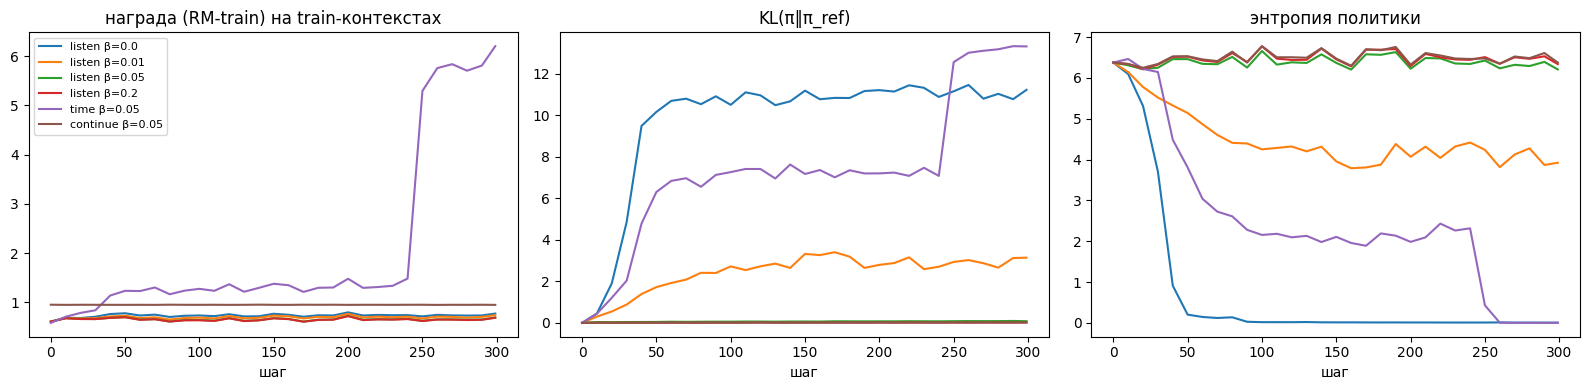

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (kind, beta), log in RL_LOGS.items():
    st = [x["step"] for x in log]
    for ax, key in zip(axes, ["reward", "kl", "entropy"]):
        ax.plot(st, [x[key] for x in log], label=f"{kind} β={beta}")
for ax, key in zip(axes, ["награда (RM-train) на train-контекстах", "KL(π‖π_ref)", "энтропия политики"]):
    ax.set_title(key); ax.set_xlabel("шаг")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rl_curves.png", dpi=120); plt.show()

## 8. Компромисс «релевантность ↔ награда»

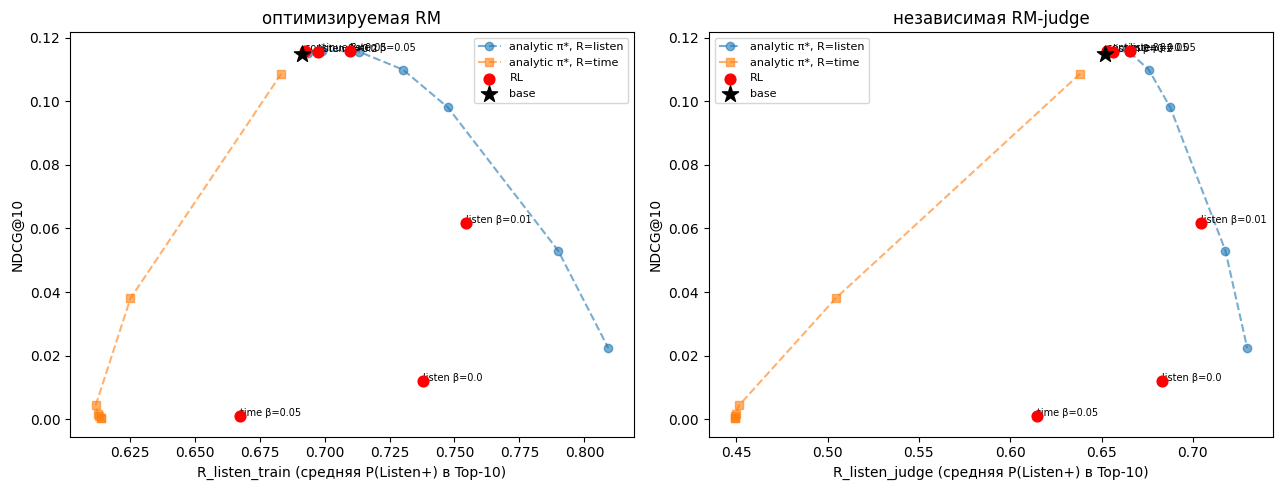

shape: (23, 15)
┌─────────────────────────────┬───────────┬─────────┬────────┬────────────────┬────────────────┬──────────────┬──────────────┬─────────────────────┬──────────┬─────────────┬────────┬───────────┬──────────────┬────────────┐
│ model                       ┆ recall@10 ┆ ndcg@10 ┆ map@10 ┆ R_listen_train ┆ R_listen_judge ┆ R_time_train ┆ R_cont_judge ┆ logged_listen+_rate ┆ coverage ┆ top1%_share ┆ gini   ┆ avg_len_s ┆ repeat_share ┆ artist_div │
│ ---                         ┆ ---       ┆ ---     ┆ ---    ┆ ---            ┆ ---            ┆ ---          ┆ ---          ┆ ---                 ┆ ---      ┆ ---         ┆ ---    ┆ ---       ┆ ---          ┆ ---        │
│ str                         ┆ f64       ┆ f64     ┆ f64    ┆ f64            ┆ f64            ┆ f64          ┆ f64          ┆ f64                 ┆ f64      ┆ f64         ┆ f64    ┆ f64       ┆ f64          ┆ f64        │
╞═════════════════════════════╪═══════════╪═════════╪════════╪════════════════╪═════════════

In [12]:
res_df = pl.DataFrame(RESULTS, infer_schema_length=None)
res_df.write_csv(f"{OUT_DIR}/results_task2.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, rcol in zip(axes, ["R_listen_train", "R_listen_judge"]):
    for kind, mk in [("listen", "o"), ("time", "s")]:
        d = res_df.filter((pl.col("method") == "analytic") & (pl.col("kind") == kind))
        ax.plot(d[rcol], d["ndcg@10"], marker=mk, ls="--", alpha=0.6, label=f"analytic π*, R={kind}")
    d = res_df.filter(pl.col("method") == "RL")
    ax.scatter(d[rcol], d["ndcg@10"], c="red", s=60, zorder=5, label="RL")
    for row in d.iter_rows(named=True):
        ax.annotate(f"{row['kind']} β={row['beta']}", (row[rcol], row["ndcg@10"]), fontsize=7)
    b = res_df.filter(pl.col("model") == "base GPT-2")
    ax.scatter(b[rcol], b["ndcg@10"], c="black", marker="*", s=150, zorder=6, label="base")
    ax.set_xlabel(f"{rcol} (средняя P(Listen+) в Top-10)"); ax.set_ylabel("NDCG@10"); ax.legend(fontsize=8)
    ax.set_title("оптимизируемая RM" if "train" in rcol else "независимая RM-judge")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pareto.png", dpi=120); plt.show()

cols = ["model", "recall@10", "ndcg@10", "map@10", "R_listen_train", "R_listen_judge", "R_time_train", "R_cont_judge",
        "logged_listen+_rate", "coverage", "top1%_share", "gini", "avg_len_s", "repeat_share", "artist_div"]
with pl.Config(tbl_rows=50, tbl_cols=20, tbl_width_chars=250):
    print(res_df.select([c for c in cols if c in res_df.columns]).with_columns(pl.col(pl.Float64).round(4)))

### Чем рекомендации RL отличаются от базовых
Пересечение Top-10 с базовой моделью и примеры треков, которые RL продвигает и понижает чаще всего.

In [13]:
base_top = BASE_LOGITS.topk(K, dim=1).indices.cpu().numpy()
diff_rows = []
for key, pol in POLICIES.items():
    lg = policy_scores(pol, EVAL["test"]["ctx"])
    top = lg.topk(K, dim=1).indices.cpu().numpy()
    overlap = np.mean([len(set(a) & set(b)) / K for a, b in zip(top, base_top)])
    gained = np.bincount(np.concatenate([np.setdiff1d(a, b) for a, b in zip(top, base_top)]), minlength=V1)
    lost = np.bincount(np.concatenate([np.setdiff1d(b, a) for a, b in zip(top, base_top)]), minlength=V1)
    g_tok, l_tok = np.argsort(-gained)[:200], np.argsort(-lost)[:200]
    diff_rows.append({"policy": f"{key[0]} β={key[1]}", "overlap@10_with_base": overlap,
                      "promoted_avg_len": float(TOK_LEN[g_tok].mean()), "demoted_avg_len": float(TOK_LEN[l_tok].mean()),
                      "promoted_avg_pop_rank": float(g_tok.mean()), "demoted_avg_pop_rank": float(l_tok.mean())})
    del lg
print(pl.DataFrame(diff_rows).with_columns(pl.col(pl.Float64).round(3)))

shape: (6, 6)
┌────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ policy         ┆ overlap@10_wit ┆ promoted_avg_l ┆ demoted_avg_l ┆ promoted_avg_ ┆ demoted_avg_p │
│ ---            ┆ h_base         ┆ en             ┆ en            ┆ pop_rank      ┆ op_rank       │
│ str            ┆ ---            ┆ ---            ┆ ---           ┆ ---           ┆ ---           │
│                ┆ f64            ┆ f64            ┆ f64           ┆ f64           ┆ f64           │
╞════════════════╪════════════════╪════════════════╪═══════════════╪═══════════════╪═══════════════╡
│ listen β=0.0   ┆ 0.014          ┆ 190.3          ┆ 175.425       ┆ 5191.93       ┆ 2218.125      │
│ listen β=0.01  ┆ 0.15           ┆ 148.75         ┆ 186.625       ┆ 2446.115      ┆ 2326.355      │
│ listen β=0.05  ┆ 0.683          ┆ 152.325        ┆ 206.225       ┆ 1874.525      ┆ 2640.7        │
│ listen β=0.2   ┆ 0.86           ┆ 159.625        ┆ 211.9         ┆ 2416.23 

## 9. Генерация на несколько шагов вперёд
Генерируем 5 треков авторегрессивно (жадно, без повторов внутри списка), каждый раз добавляя трек в контекст и GPT-2,
и RM (с откликом `UNK`, ведь реального отклика нет). Сравниваем по шагам: попадание в реальные Listen+ треки
тестового дня, награду обеих RM, энтропию и KL к базе на каждом шаге.

In [14]:
@torch.no_grad()
def generate_steps(pol, steps=5, bs=256):
    E = EVAL["test"]
    rows = []
    for i in range(0, len(E["users"]), bs):
        ctx = torch.from_numpy(E["ctx"][i:i + bs]).to(DEV)
        rt = torch.from_numpy(E["rm_tok"][i:i + bs]).to(DEV)
        rf = torch.from_numpy(E["rm_fb"][i:i + bs]).to(DEV)
        chosen = []
        for s in range(steps):
            lg = last_logits(pol, ctx)
            lb = last_logits(base, ctx)
            for c in chosen: lg.scatter_(1, c[:, None], -1e4)
            a = lg.argmax(1)
            lp, lpb = F.log_softmax(lg, -1), F.log_softmax(lb, -1)
            kl = (lp.exp() * (lp - lpb)).sum(-1)
            ent = -(lp.exp() * lp).sum(-1)
            out = {}
            for rmn, rm in [("train", rm_train), ("judge", rm_judge)]:
                h = rm.encode(rt, rf)[:, -1]
                out[rmn] = torch.sigmoid(rm.score(h, a))[:, 0]
            for j in range(len(a)):
                rows.append({"step": s + 1, "hit": int(a[j].item() in E["targets"][i + j]), "R_train": out["train"][j].item(),
                             "R_judge": out["judge"][j].item(), "kl": kl[j].item(), "entropy": ent[j].item(),
                             "len_s": float(TOK_LEN[a[j].item()]), "in_ctx": int((E["ctx"][i + j] == a[j].item()).any())})
            chosen.append(a)
            ctx = torch.cat([ctx[:, 1:], a[:, None]], 1)
            rt = torch.cat([rt[:, 1:], a[:, None]], 1)
            rf = torch.cat([rf[:, 1:], torch.full_like(a[:, None], UNK_FB)], 1)
    return pl.DataFrame(rows).group_by("step").agg(pl.all().mean()).sort("step")

for key in [None, ("listen", 0.05), ("listen", 0.0)]:
    pol = base if key is None else POLICIES.get(key)
    if pol is None: continue
    print("policy:", "base" if key is None else key)
    print(generate_steps(pol).with_columns(pl.col(pl.Float64).round(4)))

policy: base
shape: (5, 8)
┌──────┬────────┬─────────┬─────────┬────────┬─────────┬──────────┬────────┐
│ step ┆ hit    ┆ R_train ┆ R_judge ┆ kl     ┆ entropy ┆ len_s    ┆ in_ctx │
│ ---  ┆ ---    ┆ ---     ┆ ---     ┆ ---    ┆ ---     ┆ ---      ┆ ---    │
│ i64  ┆ f64    ┆ f64     ┆ f64     ┆ f64    ┆ f64     ┆ f64      ┆ f64    │
╞══════╪════════╪═════════╪═════════╪════════╪═════════╪══════════╪════════╡
│ 1    ┆ 0.1438 ┆ 0.6928  ┆ 0.6524  ┆ 0.0    ┆ 6.6459  ┆ 198.1085 ┆ 0.6924 │
│ 2    ┆ 0.1285 ┆ 0.6954  ┆ 0.6578  ┆ 0.0641 ┆ 6.5135  ┆ 196.9397 ┆ 0.6811 │
│ 3    ┆ 0.1014 ┆ 0.6954  ┆ 0.6571  ┆ 0.0956 ┆ 6.4774  ┆ 195.0814 ┆ 0.6811 │
│ 4    ┆ 0.1032 ┆ 0.6978  ┆ 0.6546  ┆ 0.1131 ┆ 6.4641  ┆ 195.7444 ┆ 0.666  │
│ 5    ┆ 0.0957 ┆ 0.6948  ┆ 0.6542  ┆ 0.1351 ┆ 6.4837  ┆ 194.8887 ┆ 0.6531 │
└──────┴────────┴─────────┴─────────┴────────┴─────────┴──────────┴────────┘
policy: ('listen', 0.05)
shape: (5, 8)
┌──────┬────────┬─────────┬─────────┬────────┬─────────┬──────────┬────────┐
│ step ┆ h

## 10. Сохранение

In [15]:
json.dump({"gpt_log": gpt_log, "gpt_time_min": GPT_TIME / 60, "rm_train": rm_train_res, "rm_judge": rm_judge_res,
           "rm_time_min": RM_TIME / 60, "rl_logs": {f"{k[0]}_{k[1]}": v for k, v in RL_LOGS.items()}},
          open(f"{OUT_DIR}/task2_logs.json", "w"), indent=1, default=float)
print("saved to", OUT_DIR)

saved to /kaggle/working/out2


## 11. Дополнение: исправление Length Hacking (`time_clipped`), долгосрочная награда без каскада скипов (`sustained`) и многошаговый RL (`multistep-3`)

В ячейках выше проявились три важных эффекта:
1. **Обратный reward hacking в `RL time β=0.05`:** линейное умножение на длину трека без ограничения сверху привело к схлопыванию на аномально длинных треках (`avg_len = 442s`, `NDCG@10 = 0.0011`). Проверим **клиппированную награду** `time_clipped`: $R(s,a) = P(\text{Listen+}\mid s,a)\cdot \frac{\min(\max(\text{len}_a, 60), 300)}{\overline{\text{len}}_{\text{clip}}}$.
2. **Каскад скипов и долгосрочная цель `sustained`:** наивный сигнал `gap_to_next ≤ 30m` положителен в `94.7%` случаев (после скипа следующий трек включается через несколько секунд). Реальный долгосрочный эффект — **каскад скипов**: после дослушанного трека вероятность дослушать следующий составляет ~82%, а после скипа падает до ~30%. Определим долгосрочный таргет `sustained`: *пользователь дослушал рекомендованный трек (`Listen+`), остался в сессии (`≤30 мин`) и дослушал следующий трек*.
3. **Честный многошаговый RL (`RL multistep-3`):** дообучение политики непосредственно на авторегрессионных роллаутах длины $H=3$ с дисконтированной суммой наград $\sum_{h=1}^3 \gamma^{h-1} R(s_h, a_h)$ ($\gamma = 0.9$).

In [15]:
# 11.1 Таблица каскада скипов по логу прослушиваний
ev_sc = ev.with_columns(
    cur_full=(pl.col("played_ratio_pct") >= 50).cast(pl.Int8),
    next_full=(pl.col("played_ratio_pct").shift(-1).over("uid") >= 50).fill_null(False).cast(pl.Int8),
).with_columns(
    sustained=((pl.col("cur_full") == 1) & (pl.col("cont") == 1) & (pl.col("next_full") == 1)).cast(pl.Int8)
)
print("Каскад скипов в обучающем периоде:")
print(ev_sc.filter(pl.col("timestamp") < valid_start).group_by("cur_full").agg(
    n=pl.len(),
    p_continue_30m=pl.col("cont").mean(),
    p_next_listen_plus=pl.col("next_full").mean(),
    p_sustained_session=pl.col("sustained").mean(),
).sort("cur_full"))

# Обновляем таргет второй головы RM на sustained session и пересобираем окна
CONT = ev_sc["sustained"].to_numpy().astype(np.float32)
W_TRAIN = rm_windows(IRM, IVS)
W_VALID = rm_windows(IVS, ITS)

# 11.2 Дообучаем RM (с таргетом sustained во второй голове) за 1 эпоху
def fit_sustained_head(rm_src, seed):
    rm = copy.deepcopy(rm_src)
    for p in rm.parameters(): p.requires_grad_(True)
    opt = torch.optim.AdamW(rm.parameters(), lr=5e-4, weight_decay=0.01)
    r = np.random.default_rng(seed)
    idx_all = r.permutation(len(W_TRAIN["tok"]))
    rm.train()
    for i in range(0, len(idx_all), 256):
        z, y1, ys, m = rm_forward(rm, W_TRAIN, idx_all[i:i + 256], True)
        loss = (F.binary_cross_entropy_with_logits(z[..., 0], y1, reduction="none")[m].mean()
                + F.binary_cross_entropy_with_logits(z[..., 1], ys, reduction="none")[m].mean())
        opt.zero_grad(); loss.backward(); opt.step()
    rm.eval()
    for p in rm.parameters(): p.requires_grad_(False)
    P1, PS, Y1, YS = [], [], [], []
    with torch.no_grad():
        for i in range(0, len(W_VALID["tok"]), 512):
            z, y1, ys, m = rm_forward(rm, W_VALID, AR(i, min(i + 512, len(W_VALID["tok"]))), False)
            P1.append(torch.sigmoid(z[..., 0])[m].cpu()); PS.append(torch.sigmoid(z[..., 1])[m].cpu())
            Y1.append(y1[m].cpu()); YS.append(ys[m].cpu())
    P1, PS, Y1, YS = (torch.cat(x).numpy() for x in (P1, PS, Y1, YS))
    return rm, {"auc_listen+": round(float(roc_auc_score(Y1, P1)), 4),
                "auc_sustained": round(float(roc_auc_score(YS, PS)), 4),
                "base_rate_sustained": round(float(YS.mean()), 4)}

rm_train, res_tr_s = fit_sustained_head(rm_train, 11)
rm_judge, res_jd_s = fit_sustained_head(rm_judge, 22)
print("RM-train (с таргетом sustained):", res_tr_s)
print("RM-judge (с таргетом sustained):", res_jd_s)

H_TEST = {"train": rm_hidden(rm_train, EVAL["test"]["rm_tok"], EVAL["test"]["rm_fb"]),
          "judge": rm_hidden(rm_judge, EVAL["test"]["rm_tok"], EVAL["test"]["rm_fb"])}
POOL_H = rm_hidden(rm_train, POOL["rm_tok"], POOL["rm_fb"])

# 11.3 Клиппированная длительность [60s, 300s] для защиты от выбросов длительности и оценка с новым таргетом sustained
TOK_LEN_CLIP = torch.tensor(np.clip(TOK_LEN, 60.0, 300.0), device=DEV)
MEAN_LEN_CLIP = float(np.clip(TOK_LEN[1:], 60.0, 300.0).mean())

def reward_from_probs(p_listen, p_sust, cand, kind):
    if kind == "listen": return p_listen
    if kind == "time_clipped": return p_listen * (TOK_LEN_CLIP[cand] / MEAN_LEN_CLIP)
    if kind == "sustained": return p_sust
    raise ValueError(kind)

report(evaluate_topk("base GPT-2 (sustained eval)", BASE_LOGITS.topk(K, dim=1).indices.cpu().numpy(),
                     {"beta": None, "kind": "base", "method": "base"}))

for kind, beta in [("time_clipped", 0.05), ("sustained", 0.05), ("sustained", 0.01)]:
    pol, log = rl_train(kind, beta)
    RL_LOGS[(kind, beta)] = log
    POLICIES[(kind, beta)] = pol
    lg = policy_scores(pol, EVAL["test"]["ctx"])
    report(evaluate_topk(f"RL {kind} β={beta}", lg.topk(K, dim=1).indices.cpu().numpy(),
                         {"beta": beta, "kind": kind, "method": "RL"}))
    del lg; gc.collect()

# 11.4 Многошаговый RL (H=3 шага авторегрессионного роллаута при обучении, γ=0.9)
def rl_train_multistep(beta=0.05, H_roll=3, gamma=0.9, steps=RL_STEPS // 2, B=RL_B // 2, G=4, lr=RL_LR,
    seed=SEED):
    torch.manual_seed(seed)
    r_ = np.random.default_rng(seed)
    pol = copy.deepcopy(base); pol.eval()
    for p in pol.parameters(): p.requires_grad_(True)
    opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0.0)
    t0 = time.time()
    r_start, r_end, kl_end = None, None, 0.0
    for step in range(steps):
        bi = r_.choice(len(POOL["ctx"]), B, replace=False)
        ctx = torch.from_numpy(POOL["ctx"][bi]).to(DEV).repeat_interleave(G, 0)
        rt = torch.from_numpy(POOL["rm_tok"][bi]).to(DEV).repeat_interleave(G, 0)
        rf = torch.from_numpy(POOL["rm_fb"][bi]).to(DEV).repeat_interleave(G, 0)
        logp_sum = torch.zeros(B * G, device=DEV)
        kl_sum = torch.zeros(B * G, device=DEV)
        ret = torch.zeros(B * G, device=DEV)
        for h in range(H_roll):
            with torch.no_grad():
                ref_lp = F.log_softmax(last_logits(base, ctx), -1)
            lp = F.log_softmax(last_logits(pol, ctx), -1)
            a = torch.multinomial(lp.exp().detach(), 1).squeeze(1)
            logp_sum = logp_sum + lp.gather(1, a[:, None]).squeeze(1)
            kl_sum = kl_sum + (lp.exp() * (lp - ref_lp)).sum(-1)
            with torch.no_grad():
                h_rm = rm_train.encode(rt, rf)[:, -1]
                r_step = torch.sigmoid(rm_train.score(h_rm, a))[..., 1]  # sustained reward
                ret = ret + (gamma ** h) * r_step
            ctx = torch.cat([ctx[:, 1:], a[:, None]], 1)
            rt = torch.cat([rt[:, 1:], a[:, None]], 1)
            rf = torch.cat([rf[:, 1:], torch.full_like(a[:, None], UNK_FB)], 1)
        ret_g = ret.view(B, G)
        adv = (ret_g - ret_g.mean(1, keepdim=True)).reshape(-1)
        loss = -(adv * logp_sum).mean() / H_roll + beta * (kl_sum.mean() / H_roll)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
        if step == 0: r_start = ret.mean().item()
        r_end, kl_end = ret.mean().item(), (kl_sum.mean() / H_roll).item()
    print(f"RL multistep-{H_roll} (sustained) β={beta}: 3-step return {r_start:.4f} → {r_end:.4f}, KL/step "
      f"{kl_end:.3f} ({time.time() - t0:.0f}s)")
    return pol
# Уменьшаем размер батча B в 2 раза (до 32). Суммарный батч станет 32 * 4 = 128, что легко влезет в GPU.
pol_ms = rl_train_multistep(beta=0.05, B=RL_B // 4) 

POLICIES[("multistep3_sustained", 0.05)] = pol_ms
lg_ms = policy_scores(pol_ms, EVAL["test"]["ctx"])
report(evaluate_topk("RL multistep-3 sustained β=0.05", lg_ms.topk(K, dim=1).indices.cpu().numpy(),
                     {"beta": 0.05, "kind": "multistep3_sustained", "method": "RL"}))
print("\nСводная таблица по новым моделям (где R_cont_judge теперь = P(sustained)):")
res_df2 = pl.DataFrame(RESULTS[-5:], infer_schema_length=None)
cols2 = ["model", "recall@10", "ndcg@10", "R_listen_train", "R_listen_judge", "R_cont_judge",
         "logged_listen+_rate", "coverage", "top1%_share", "avg_len_s", "repeat_share", "artist_div"]
with pl.Config(tbl_rows=20, tbl_cols=20, tbl_width_chars=250):
    print(res_df2.select([c for c in cols2 if c in res_df2.columns]).with_columns(pl.col(pl.Float64).round(4)))
print("\n5-шаговая генерация для RL multistep-3 sustained β=0.05:")
print(generate_steps(pol_ms).with_columns(pl.col(pl.Float64).round(4)))

Каскад скипов в обучающем периоде:
shape: (2, 5)
┌──────────┬──────────┬────────────────┬────────────────────┬─────────────────────┐
│ cur_full ┆ n        ┆ p_continue_30m ┆ p_next_listen_plus ┆ p_sustained_session │
│ ---      ┆ ---      ┆ ---            ┆ ---                ┆ ---                 │
│ i8       ┆ u32      ┆ f64            ┆ f64                ┆ f64                 │
╞══════════╪══════════╪════════════════╪════════════════════╪═════════════════════╡
│ 0        ┆ 12013716 ┆ 0.957622       ┆ 0.310875           ┆ 0.0                 │
│ 1        ┆ 21102777 ┆ 0.942479       ┆ 0.822957           ┆ 0.786749            │
└──────────┴──────────┴────────────────┴────────────────────┴─────────────────────┘
RM-train (с таргетом sustained): {'auc_listen+': 0.8644, 'auc_sustained': 0.8558, 'base_rate_sustained': 0.5261}
RM-judge (с таргетом sustained): {'auc_listen+': 0.865, 'auc_sustained': 0.8566, 'base_rate_sustained': 0.5261}
base GPT-2 (sustained eval)        recall@10=0.1167 nd

## 12. Продвинутое исследование по мотивам статей из условия (`arXiv:2403.04875` и `arXiv:2607.02818`)

Реализуем и сравним четыре ключевых механизма из двух референсных работ задания:
1. **Beyond-Accuracy Alignment ([Petrov & Macdonald, 2024, arXiv:2403.04875](https://arxiv.org/pdf/2403.04875)):** композитная награда $R_{\text{beyond}}(s,a) = \frac{1}{2}\big(P(\text{Listen+}) + P(\text{sustained})\big) - \alpha \cdot \text{pop\_norm}(a)$, которая увеличивает долгосрочное удержание и одновременно **снижает смещение к популярным хитам (`top1%_share`)**, расширяя покрытие каталога и разнообразие артистов.
2. **Off-Policy Session-Level REINFORCE с многошаговой коррекцией важности ([Matveev et al., 2026, arXiv:2607.02818](https://arxiv.org/pdf/2607.02818)):** обучение на реальных залогированных траекториях сессий длины $H=4$ с дисконтированной суммой наград $G_{t:t+H} = \sum_{h=0}^{H-1} \gamma^h r_{t+h}^{\text{log}}$ и клиппированными многошаговыми весами важности $\rho_{0:h} = \min\!\big(c_{\max}, \prod_{k=0}^h \frac{\pi_\theta(a_{t+k}\mid s_{t+k})}{\pi_{\text{ref}}(a_{t+k}\mid s_{t+k})}\big)$.
3. **Feedback-Model-Based Test-Time Scaling (2-step Lookahead, [arXiv:2607.02818](https://arxiv.org/pdf/2607.02818)) и роллаут с симуляцией отклика пользователя:** выбор рекомендаций на инференсе с двухшаговым прогнозом кумулятивной награды через симулятор отклика RM (`fb_sim` вместо `UNK_FB`).
4. **Doubly Robust (DR) и SNIPS Off-Policy Evaluation (OPE, [arXiv:2607.02818](https://arxiv.org/pdf/2607.02818)):** контрфактическая офлайн-оценка всех политик на тестовом логе с использованием `base GPT-2` как поведенческой политики $\hat{\pi}_b$ и независимой `RM-judge` как контрольной вариаты.

In [16]:
import math
import copy
import torch
import torch.nn.functional as F
import numpy as np
import polars as pl

# 12.1 Beyond-Accuracy RL (arXiv:2403.04875): дебайасинг популярности + удержание сессии
LOG_POP_NORM = torch.tensor(np.log1p(TOK_POP) / max(1.0, float(np.log1p(TOK_POP[1:]).max())), dtype=torch.float32, device=DEV)

def reward_from_probs(p_listen, p_sust, cand, kind):
    if kind == "listen": return p_listen
    if kind == "time_clipped": return p_listen * (TOK_LEN_CLIP[cand] / MEAN_LEN_CLIP)
    if kind == "sustained": return p_sust
    if kind == "beyond_pop": return 0.5 * (p_listen + p_sust) - 0.12 * LOG_POP_NORM[cand]
    raise ValueError(kind)

pol_ba, log_ba = rl_train("beyond_pop", 0.05)
RL_LOGS[("beyond_pop", 0.05)] = log_ba
POLICIES[("beyond_pop", 0.05)] = pol_ba
lg_ba = policy_scores(pol_ba, EVAL["test"]["ctx"])
report(evaluate_topk("RL beyond_pop β=0.05 (2403.04875)", lg_ba.topk(K, dim=1).indices.cpu().numpy(),
                     {"beta": 0.05, "kind": "beyond_pop", "method": "RL"}))
del lg_ba; gc.collect()

# 12.2 Off-Policy Session-Level REINFORCE с многошаговыми весами важности (arXiv:2607.02818)
def rl_train_offpolicy_session(beta=0.05, H_sess=4, gamma=0.9, c_max=3.0, steps=RL_STEPS // 2, B=RL_B, lr=RL_LR, seed=SEED):
    torch.manual_seed(seed)
    r_ = np.random.default_rng(seed)
    valid_u = np.where(IVS > L + H_sess + 5)[0]
    pol = copy.deepcopy(base); pol.eval()
    for p in pol.parameters(): p.requires_grad_(True)
    opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0.0)
    t0 = time.time()
    w_mean_log, kl_log = 1.0, 0.0
    for step in range(steps):
        us = r_.choice(valid_u, B, replace=True)
        ends = (r_.random(B) * (IVS[us] - L - H_sess) + L + H_sess).astype(np.int64)
        seq = torch.from_numpy(gather(TOK, us, ends - L, L)).to(DEV)
        # Реальные залогированные награды на последних H_sess шагах: 0.5*(Listen+ + sustained)
        r_pl = (gather(PLAYED, us, ends - H_sess, H_sess) >= 50).astype(np.float32)
        r_su = gather(CONT, us, ends - H_sess, H_sess).astype(np.float32)
        r_mat = torch.from_numpy(0.5 * (r_pl + r_su)).to(DEV)  # [B, H_sess]
        G_ret = torch.zeros_like(r_mat)
        running = torch.zeros(B, device=DEV)
        for h in range(H_sess - 1, -1, -1):
            running = r_mat[:, h] + gamma * running
            G_ret[:, h] = running
        adv = (G_ret - G_ret.mean(0, keepdim=True)) / (G_ret.std(0, keepdim=True) + 1e-6)

        mask = (seq != 0).long()
        pos = (mask.cumsum(1) - 1).clamp(min=0)
        with torch.no_grad():
            h_ref = base.transformer(input_ids=seq, attention_mask=mask, position_ids=pos).last_hidden_state[:, -H_sess - 1:-1]
            lg_ref = base.lm_head(h_ref).float(); lg_ref[..., 0] = -1e4
            lp_ref = F.log_softmax(lg_ref, -1)
        h_pol = pol.transformer(input_ids=seq, attention_mask=mask, position_ids=pos).last_hidden_state[:, -H_sess - 1:-1]
        lg_pol = pol.lm_head(h_pol).float(); lg_pol[..., 0] = -1e4
        lp_pol = F.log_softmax(lg_pol, -1)

        acts = seq[:, -H_sess:].unsqueeze(-1)  # [B, H_sess, 1]
        logp_a = lp_pol.gather(-1, acts).squeeze(-1)
        logp_ref_a = lp_ref.gather(-1, acts).squeeze(-1)
        # Многошаговый вес важности prod_{k=0..h} pi(a_k|s_k)/pi_ref(a_k|s_k) с клиппингом
        log_rho_cum = torch.cumsum((logp_a.detach() - logp_ref_a), dim=1).clamp(-3.0, math.log(c_max))
        imp_w = torch.exp(log_rho_cum)

        pg_loss = -(imp_w * adv * logp_a).mean()
        kl_loss = (lp_pol.exp() * (lp_pol - lp_ref)).sum(-1).mean()
        loss = pg_loss + beta * kl_loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
        w_mean_log, kl_log = imp_w.mean().item(), kl_loss.item()
    print(f"Off-Policy Session REINFORCE (H={H_sess}, β={beta}): mean_imp_w={w_mean_log:.3f}, KL={kl_log:.4f} ({(time.time() - t0):.0f}s)")
    return pol

pol_op = rl_train_offpolicy_session(beta=0.05)
POLICIES[("offpolicy_session", 0.05)] = pol_op
lg_op = policy_scores(pol_op, EVAL["test"]["ctx"])
report(evaluate_topk("RL off-policy session (2607.02818)", lg_op.topk(K, dim=1).indices.cpu().numpy(),
                     {"beta": 0.05, "kind": "offpolicy_session", "method": "RL"}))
del lg_op; gc.collect()

# 12.3 Feedback-Model-Based Test-Time Scaling: 2-шаговый Lookahead с симуляцией отклика пользователя (arXiv:2607.02818)
@torch.no_grad()
def lookahead_topk(base_logits, M=25, beta=0.15, gamma=0.5, bs=64):
    E = EVAL["test"]
    cand1 = base_logits.topk(M, dim=1).indices  # [U, M]
    cand2 = base_logits.topk(10, dim=1).indices # [U, 10] для оценки ценности следующего состояния V(s_{t+1})
    out_topk = []
    for i in range(0, len(E["users"]), bs):
        b_c1 = cand1[i:i + bs]                  # [b, M]
        b_c2 = cand2[i:i + bs]                  # [b, 10]
        b = len(b_c1)
        h0 = H_TEST["train"][i:i + bs]          # [b, d]
        p0 = torch.sigmoid(rm_train.score(h0[:, None, :], b_c1))
        r1 = 0.5 * (p0[..., 0] + p0[..., 1])    # [b, M]
        # Симулируем отклик пользователя fb_sim ∈ {1,2,3,4} по предсказанной вероятности дослушивания
        fb_sim = torch.where(p0[..., 0] < 0.35, 1, torch.where(p0[..., 0] < 0.50, 2, torch.where(p0[..., 0] < 0.75, 3, 4))).long()
        rt = torch.from_numpy(E["rm_tok"][i:i + bs, -24:]).to(DEV)[:, None, :].expand(b, M, -1).reshape(b * M, -1)
        rf = torch.from_numpy(E["rm_fb"][i:i + bs, -24:]).to(DEV)[:, None, :].expand(b, M, -1).reshape(b * M, -1)
        rt_next = torch.cat([rt[:, 1:], b_c1.reshape(-1, 1)], 1)
        rf_next = torch.cat([rf[:, 1:], fb_sim.reshape(-1, 1)], 1)
        h1 = rm_train.encode(rt_next, rf_next)[:, -1].view(b, M, -1)  # [b, M, d]
        p1 = torch.sigmoid(rm_train.score(h1[:, :, None, :], b_c2[:, None, :].expand(b, M, -1)))
        v_next = (0.5 * (p1[..., 0] + p1[..., 1])).max(dim=-1).values # [b, M]
        score = base_logits[i:i + bs].gather(1, b_c1) + (r1 + gamma * v_next) / beta
        best_idx = score.topk(K, dim=1).indices
        out_topk.append(b_c1.gather(1, best_idx).cpu())
    return torch.cat(out_topk).numpy()

tk_la = lookahead_topk(BASE_LOGITS)
report(evaluate_topk("TTS 2-step Lookahead (2607.02818)", tk_la, {"beta": 0.15, "kind": "tts_lookahead", "method": "TTS"}))

# 12.4 Doubly Robust (DR) и SNIPS Off-Policy Evaluation (OPE) на тестовом логе (arXiv:2607.02818)
@torch.no_grad()
def evaluate_ope(name, pol_logits, topk_arr):
    E = EVAL["test"]
    prob_b = F.softmax(BASE_LOGITS, -1)
    prob_p = F.softmax(pol_logits, -1)
    tk = torch.from_numpy(topk_arr).to(DEV)
    q_tk = torch.sigmoid(rm_judge.score(H_TEST["judge"][:, None, :], tk))[..., 0]
    dm_vals = q_tk.mean(1).cpu().numpy()

    w_list, r_list, res_list = [], [], []
    for i, pl_dict in enumerate(E["played"]):
        items = list(pl_dict.keys())
        if not items: continue
        it_t = torch.tensor(items, dtype=torch.long, device=DEV)
        r_obs = torch.tensor([1.0 if pl_dict[x] >= 50 else 0.0 for x in items], device=DEV)
        q_hat = torch.sigmoid(rm_judge.score(H_TEST["judge"][i:i + 1, None, :], it_t[None, :]))[0, :, 0]
        w = (prob_p[i, it_t] / (prob_b[i, it_t] + 1e-8)).clamp(max=10.0)
        w_list.append(w.cpu().numpy())
        r_list.append(r_obs.cpu().numpy())
        res_list.append((r_obs - q_hat).cpu().numpy())
        
    W_all = np.concatenate(w_list)
    R_all = np.concatenate(r_list)
    Res_all = np.concatenate(res_list)
    
    dm = float(dm_vals.mean())
    snips = float((W_all * R_all).sum() / (W_all.sum() + 1e-8))
    dr = float(dm + (W_all * Res_all).sum() / (W_all.sum() + 1e-8))
    
    return {
        "model": name, 
        "OPE_DM (judge)": round(dm, 4), 
        "OPE_SNIPS": round(snips, 4), 
        "OPE_DR": round(dr, 4)
    }

# Пример вызова OPE для проверки работоспособности функции
# Пример вызова OPE для проверки работоспособности функции
lg_ba_eval = policy_scores(pol_ba, EVAL["test"]["ctx"])
print(evaluate_ope("RL beyond_pop", lg_ba_eval, tk_la))
del lg_ba_eval; gc.collect()

RL beyond_pop β=0.05: reward 0.4624 → 0.5399, KL 0.089, entropy 6.38 → 6.34  (117s)
RL beyond_pop β=0.05 (2403.04875)  recall@10=0.1142 ndcg@10=0.1135 R_listen_train=0.7170 R_listen_judge=0.7169 logged_listen+_rate=0.7807 coverage=0.4252 top1%_share=0.0954 avg_len_s=182.8840 repeat_share=0.4838
Off-Policy Session REINFORCE (H=4, β=0.05): mean_imp_w=0.758, KL=0.3567 (57s)
RL off-policy session (2607.02818) recall@10=0.1069 ndcg@10=0.1074 R_listen_train=0.7033 R_listen_judge=0.7083 logged_listen+_rate=0.7780 coverage=0.3944 top1%_share=0.1320 avg_len_s=183.7189 repeat_share=0.4697
TTS 2-step Lookahead (2607.02818)  recall@10=0.1154 ndcg@10=0.1146 R_listen_train=0.7196 R_listen_judge=0.7157 logged_listen+_rate=0.7769 coverage=0.4306 top1%_share=0.1209 avg_len_s=187.0056 repeat_share=0.4931
